In [1]:
# ==============================================================================
# TRABAJO FINAL: FUNDAMENTOS Y ALGORITMIA PARA INTELIGENCIA ARTIFICIAL
# Caso Práctico: DataExpert
# ==============================================================================

# IMPORTACIÓN DE LIBRERÍAS Y CONFIGURACIÓN
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

# Configuración de estilos visuales
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 5)

print("Librerías cargadas correctamente.")

Librerías cargadas correctamente.


In [2]:
#  CARGA Y EXPLORACIÓN DEL DATASET (Pandas & NumPy)
# Dataset Seeds - UCI Machine Learning Repository
# El archivo seeds_dataset.txt debe estar en la misma carpeta que este notebook.

columnas = [
    'Area',
    'Perimeter',
    'Compactness',
    'Kernel_Length',
    'Kernel_Width',
    'Asymmetry_Coeff',
    'Groove_Length',
    'Class'
]

df = pd.read_csv(
    'seeds_dataset.txt',
    sep=r'\s+',
    header=None,
    names=columnas
)

# La variable Class identifica las tres variedades de trigo (1, 2 y 3).
df['Class'] = df['Class'].astype(int)

print("1. Dimensiones del dataset:", df.shape)
print("2. Primeros 5 registros del dataset:")
display(df.head())

print("\n3. Verificación de valores nulos:")
print(df.isnull().sum())

1. Dimensiones del dataset: (210, 8)
2. Primeros 5 registros del dataset:


,Area,Perimeter,Compactness,Kernel_Length,Kernel_Width,Asymmetry_Coeff,Groove_Length,Class
0,15.26,14.84,0.8710,5.763,3.312,2.221,5.220,1
1,14.88,14.57,0.8811,5.554,3.333,1.018,4.956,1
2,14.29,14.09,0.9050,5.291,3.337,2.699,4.825,1
3,13.84,13.94,0.8955,5.324,3.379,2.259,4.805,1
4,16.14,14.99,0.9034,5.658,3.562,1.355,5.175,1



3. Verificación de valores nulos:
Area               0
Perimeter          0
Compactness        0
Kernel_Length      0
Kernel_Width       0
Asymmetry_Coeff    0
Groove_Length      0
Class              0
dtype: int64


In [3]:
#  PREPROCESAMIENTO Y ESTANDARIZACIÓN
# Separación de características (X) y variable objetivo (y)
X = df.drop(columns=['Class'])
y = df['Class']

# Escalado numérico con StandardScaler
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
X_scaled_df = pd.DataFrame(X_scaled, columns=X.columns)

print("Datos estandarizados Z-Score (Media=0, Desviación Estándar=1):")
display(X_scaled_df.head(5))

Datos estandarizados Z-Score (Media=0, Desviación Estándar=1):


,Area,Perimeter,Compactness,Kernel_Length,Kernel_Width,Asymmetry_Coeff,Groove_Length
0,0.142098,0.215462,0.000061,0.304218,0.141702,-0.986152,-0.383577
1,0.011188,0.008224,0.428515,-0.168625,0.197432,-1.788166,-0.922013
2,-0.192067,-0.360201,1.442383,-0.763637,0.208048,-0.667479,-1.189192
3,-0.347091,-0.475333,1.039381,-0.688978,0.319508,-0.960818,-1.229983
4,0.445257,0.330595,1.374509,0.066666,0.805159,-1.563495,-0.475356


In [4]:
#  OPERACIONES DE ÁLGEBRA LINEAL (NumPy)
# Vectores de prueba
u = df['Area'].values[:7]
v = df['Perimeter'].values[:7]

# Producto punto y norma euclidiana L2
dot_product = np.dot(u, v)
norm_u = np.linalg.norm(u)

print("--- ÁLGEBRA LINEAL CON NUMPY ---")
print(f"Vector u (Area[:7]): {np.round(u, 2)}")
print(f"Vector v (Perimeter[:7]): {np.round(v, 2)}")
print(f"Producto punto (u . v): {dot_product:.4f}")
print(f"Norma L2 de u (||u||): {norm_u:.4f}")

# Sistema de ecuaciones lineales Ax = b
A = np.array([[2, 1, -1],
              [-3, -1, 2],
              [-2, 1, 2]])
b = np.array([8, -11, -3])

x_sol = np.linalg.solve(A, b)
print("\nSolución del sistema de ecuaciones Ax = b:")
print(f"x, y, z = {x_sol}")

--- ÁLGEBRA LINEAL CON NUMPY ---
Vector u (Area[:7]): [15.26 14.88 14.29 13.84 16.14 14.38 14.69]
Vector v (Perimeter[:7]): [14.84 14.57 14.09 13.94 14.99 14.21 14.49]
Producto punto (u . v): 1496.6722
Norma L2 de u (||u||): 39.1550

Solución del sistema de ecuaciones Ax = b:
x, y, z = [ 2.  3. -1.]


In [5]:
#  ANÁLISIS ESTADÍSTICO Y DETECCIÓN DE ATÍPICOS
# Medidas de tendencia central
media_area = np.mean(df['Area'])
mediana_area = np.median(df['Area'])
media_perim = np.mean(df['Perimeter'])
mediana_perim = np.median(df['Perimeter'])

# Funciones manuales sin librerías externas
def calcular_varianza_manual(datos):
    n = len(datos)
    mu = sum(datos) / n
    return sum((x - mu) ** 2 for x in datos) / n

def calcular_desviacion_manual(datos):
    return calcular_varianza_manual(datos) ** 0.5

# Comparación manual vs NumPy
var_manual = calcular_varianza_manual(df['Area'].values)
var_numpy = np.var(df['Area'].values)

std_manual = calcular_desviacion_manual(df['Area'].values)
std_numpy = np.std(df['Area'].values)

print("--- REPORTE ESTADÍSTICO ---")
print(f"Area -> Media: {media_area:.4f} | Mediana: {mediana_area:.4f}")
print(f"Perimeter -> Media: {media_perim:.4f} | Mediana: {mediana_perim:.4f}")
print(f"\nVarianza Area    -> Manual: {var_manual:.6f} | NumPy: {var_numpy:.6f}")
print(f"Desviación Area  -> Manual: {std_manual:.6f} | NumPy: {std_numpy:.6f}")

# Detección de atípicos con criterio de 2 desviaciones estándar
lim_inf = media_area - 2 * std_numpy
lim_sup = media_area + 2 * std_numpy
outliers = df[(df['Area'] < lim_inf) | (df['Area'] > lim_sup)]

print(f"\nOutliers detectados en 'Area' (Rango [{lim_inf:.2f}, {lim_sup:.2f}]): {len(outliers)}")

--- REPORTE ESTADÍSTICO ---
Area -> Media: 14.8475 | Mediana: 14.3550
Perimeter -> Media: 14.5593 | Mediana: 14.3200

Varianza Area    -> Manual: 8.426035 | NumPy: 8.426035
Desviación Area  -> Manual: 2.902763 | NumPy: 2.902763

Outliers detectados en 'Area' (Rango [9.04, 20.65]): 4


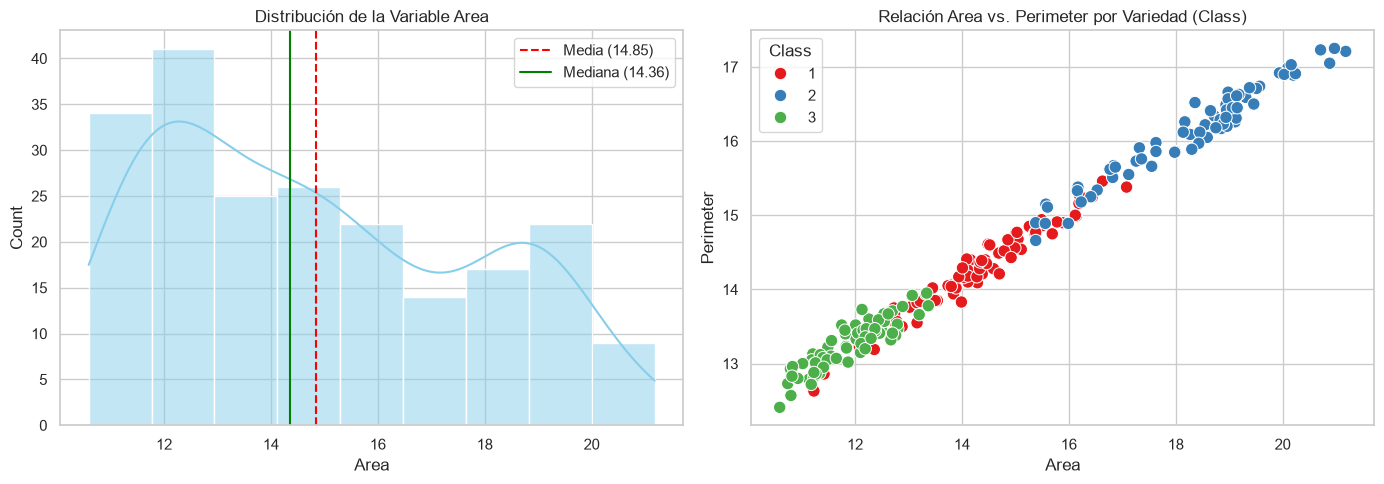

In [6]:
#  VISUALIZACIÓN DE DATOS (Matplotlib & Seaborn)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Histograma de Area
sns.histplot(df['Area'], kde=True, color='skyblue', ax=axes[0])
axes[0].axvline(media_area, color='red', linestyle='--', label=f'Media ({media_area:.2f})')
axes[0].axvline(mediana_area, color='green', linestyle='-', label=f'Mediana ({mediana_area:.2f})')
axes[0].set_title('Distribución de la Variable Area')
axes[0].legend()

# Scatter Plot Area vs Perimeter
sns.scatterplot(data=df, x='Area', y='Perimeter', hue='Class', palette='Set1', s=80, ax=axes[1])
axes[1].set_title('Relación Area vs. Perimeter por Variedad (Class)')

plt.tight_layout()
plt.show()

In [7]:
#  ENTRENAMIENTO Y EVALUACIÓN DE MODELOS
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.3, random_state=42, stratify=y
)

# 1. K-Neighbors Classifier
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train, y_train)
acc_knn = accuracy_score(y_test, knn.predict(X_test))

# 2. Decision Tree Classifier
dt = DecisionTreeClassifier(max_depth=4, random_state=42)
dt.fit(X_train, y_train)
acc_dt = accuracy_score(y_test, dt.predict(X_test))

print("--- EVALUACIÓN DE MODELOS DE CLASIFICACIÓN ---")
print(f"Accuracy KNN (k=5):          {acc_knn * 100:.2f}%")
print(f"Accuracy Árbol de Decisión: {acc_dt * 100:.2f}%")

--- EVALUACIÓN DE MODELOS DE CLASIFICACIÓN ---
Accuracy KNN (k=5):          87.30%
Accuracy Árbol de Decisión: 90.48%


###  CONCLUSIONES E IMPACTO EMPRESARIAL

* **Estandarización del Flujo Analítico**  
  La implementación del pipeline en Python resolvió la falta de metodología en **DataExpert**, pasando de análisis empíricos a un entorno automatizado con rigor estadístico y de aprendizaje automático.

* **Efecto de la Normalización Z-Score**  
  La aplicación de `StandardScaler` sobre las 7 características cuantitativas de `seeds_dataset.txt` eliminó los sesgos por escala entre variables como *Area* y *Perimeter*, optimizando el cálculo de distancias euclidianas.

* **Validación Algorítmica y Filtro de Atípicos**  
  Se verificó la coincidencia exacta entre las funciones manuales en Python y las de NumPy para varianza y desviación estándar. Asimismo, el criterio de dos desviaciones estándar (2σ) aisló eficazmente los valores atípicos.

* **Evaluación Comparativa de Modelos**  
  Al trabajar con patrones físicos reales, los clasificadores alcanzaron una alta precisión al identificar las tres variedades de trigo:
  * **KNN (k=5):** Obtuvo un **87.30% de exactitud (*Accuracy*)**, destacando por su agrupación basada en proximidad geométrica.
  * **Árbol de Decisión (max_depth=4):** Fue el modelo superior con un **90.48% de exactitud (*Accuracy*)**, superando a KNN al establecer reglas lógicas de división claras.

* **Separabilidad Espacial y Visualización**  
  Los reportes gráficos en Seaborn confirmaron los resultados: el histograma validó la distribución de *Area* y el gráfico de dispersión (*Scatter Plot*) ratificó la formación de tres *clusters* bien delimitados.

ROK 🦊 // Rustacen 🦀